# Image Data Collection and Processing

**Goal:** turn each team member's facial photos into a feature table (`output/image_features.csv`) that the facial recognition model will use, with `member_id` as the label.

**Pipeline:**
1. **Load and check:** find every member folder, confirm it has the 3 expressions, and resize all images to one shape.
2. **Augment:** create 4 variations of every image so the model learns identity, not one exact photo.
3. **Extract features:** detect and crop the face, compute intensity, colour, texture (LBP) and shape (HOG) features, and save them to CSV.

**Folder layout:**
```
image_processing/
├── images/<member>/{neutral,smiling,surprised}.jpg   # input
├── augmented_images/<member>/<expression>_<aug>.jpg  # generated
├── output/image_features.csv                         # generated
└── image_preprocessing.ipynb
```
Members are discovered automatically, so a new member only needs a folder with 3 photos.

## 1. Load and display images
**Setup:** imports and shared settings. Every image is resized to `256×256` so all images have the same shape.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMAGE_DIR = "images"
EXPRESSIONS = ["neutral", "smiling", "surprised"]
VALID_EXT = (".jpg", ".jpeg", ".png")
TARGET_SIZE = (256, 256)  # every image resized to the same dimensions

**Find members and check files:** scans `images/` for one folder per member and checks that each has `neutral`, `smiling` and `surprised` (`.jpg`, `.jpeg` or `.png`). Missing files are flagged before any processing.

In [2]:
def find_image(member_dir, expression):
    """Return the path for an expression, accepting .jpg/.jpeg/.png."""
    for ext in VALID_EXT:
        path = os.path.join(member_dir, expression + ext)
        if os.path.exists(path):
            return path
    return None


def discover_members(image_dir=IMAGE_DIR):
    """Scan images/ and report which members have all 3 expressions."""
    members = {}
    for name in sorted(os.listdir(image_dir)):
        member_dir = os.path.join(image_dir, name)
        if not os.path.isdir(member_dir):
            continue
        paths = {exp: find_image(member_dir, exp) for exp in EXPRESSIONS}
        missing = [exp for exp, p in paths.items() if p is None]
        if missing:
            print(f"⚠ {name}: missing {missing}")
        else:
            print(f"✓ {name}: all 3 expressions found")
        members[name] = {exp: p for exp, p in paths.items() if p}
    return members


members = discover_members()
print(f"\nTotal members found: {len(members)}")

✓ Anglebert: all 3 expressions found
✓ Mukasa: all 3 expressions found
✓ Nina: all 3 expressions found

Total members found: 3


**Load and standardise:** reads each image with OpenCV and converts BGR to RGB (OpenCV loads colours in BGR order). Photos come in different shapes (portrait and landscape), so each one is first **padded to a square** with its median colour and then resized to 256×256. Stretching the photo instead would squash the face and make face detection fail. The printout confirms every image has the same shape.

In [3]:
def pad_to_square(image):
    """Pad the short side with the image's median colour so resizing doesn't squash the face."""
    h, w = image.shape[:2]
    side = max(h, w)
    top, left = (side - h) // 2, (side - w) // 2
    fill = [int(v) for v in np.median(image.reshape(-1, 3), axis=0)]
    return cv2.copyMakeBorder(image, top, side - h - top, left, side - w - left,
                              cv2.BORDER_CONSTANT, value=fill)


def load_image(path, size=TARGET_SIZE):
    """Load an image as RGB, pad it to a square and resize so all images share one shape."""
    image = cv2.imread(path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return cv2.resize(pad_to_square(image), size, interpolation=cv2.INTER_AREA)


images = {
    member: {exp: load_image(path) for exp, path in paths.items()}
    for member, paths in members.items()
}

for member, exps in images.items():
    for exp, img in exps.items():
        print(f"{member:12s} {exp:10s} shape={img.shape} dtype={img.dtype}")

Anglebert    neutral    shape=(256, 256, 3) dtype=uint8
Anglebert    smiling    shape=(256, 256, 3) dtype=uint8
Anglebert    surprised  shape=(256, 256, 3) dtype=uint8
Mukasa       neutral    shape=(256, 256, 3) dtype=uint8
Mukasa       smiling    shape=(256, 256, 3) dtype=uint8
Mukasa       surprised  shape=(256, 256, 3) dtype=uint8
Nina         neutral    shape=(256, 256, 3) dtype=uint8
Nina         smiling    shape=(256, 256, 3) dtype=uint8
Nina         surprised  shape=(256, 256, 3) dtype=uint8


**Display grid:** shows one row per member and one column per expression, as a visual check of the dataset.

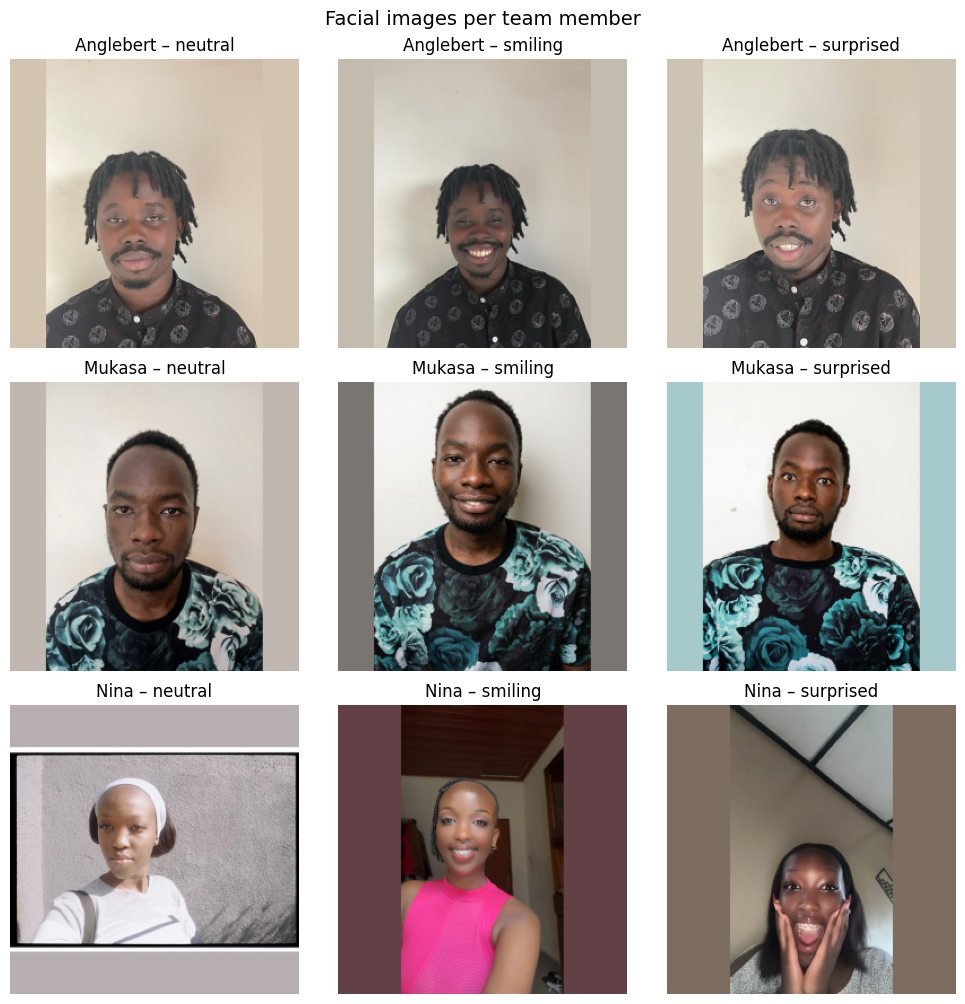

In [4]:
def display_member_grid(images):
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.4 * n), squeeze=False)
    for row, (member, exps) in enumerate(images.items()):
        for col, exp in enumerate(EXPRESSIONS):
            ax = axes[row][col]
            if exp in exps:
                ax.imshow(exps[exp])
            else:
                ax.text(0.5, 0.5, "missing", ha="center", va="center")
            ax.set_title(f"{member} – {exp}")
            ax.axis("off")
    plt.suptitle("Facial images per team member", fontsize=14)
    plt.tight_layout()
    plt.show()


display_member_grid(images)

## 2. Augmentation
**Augmentation functions:** four transforms, each simulating something a face-recognition system meets in practice:

| Augmentation | Parameters | Why |
|---|---|---|
| Horizontal flip | mirror on vertical axis | mirrored pose |
| Rotation | 15°, reflected borders | head tilt (reflection avoids black corners) |
| Grayscale | kept as 3 channels | removes dependence on colour/lighting tone |
| Brightness/contrast | α = 1.2, β = 30 | different lighting |

In [5]:
AUG_DIR = "augmented_images"


def flip_horizontal(image):
    return cv2.flip(image, 1)


def rotate(image, angle=15):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    # BORDER_REFLECT avoids black corners after rotation
    return cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)


def to_grayscale(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Keep 3 channels so every image has the same shape for feature extraction
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)


def adjust_brightness(image, alpha=1.2, beta=30):
    """alpha = contrast multiplier, beta = brightness offset."""
    return cv2.convertScaleAbs(image, alpha=alpha, beta=beta)


AUGMENTATIONS = {
    "flipped": flip_horizontal,
    "rotated": rotate,
    "grayscale": to_grayscale,
    "bright": adjust_brightness,
}

**Apply and save:** runs all 4 augmentations on every original and saves the results to `augmented_images/<member>/<expression>_<augmentation>.jpg`. The originals are kept in memory alongside them, giving 5 versions of each image.

In [6]:
def augment_all(images):
    """Return {member: {expression: {aug_name: image}}}, including the original."""
    augmented = {}
    for member, exps in images.items():
        member_dir = os.path.join(AUG_DIR, member)
        os.makedirs(member_dir, exist_ok=True)
        augmented[member] = {}

        for exp, img in exps.items():
            versions = {"original": img}
            for aug_name, fn in AUGMENTATIONS.items():
                versions[aug_name] = fn(img)

            for aug_name, aug_img in versions.items():
                if aug_name == "original":
                    continue
                out_path = os.path.join(member_dir, f"{exp}_{aug_name}.jpg")
                cv2.imwrite(out_path, cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

            augmented[member][exp] = versions
    return augmented


augmented = augment_all(images)

total = sum(len(v) for exps in augmented.values() for v in exps.values())
print(f"Total images (originals + augmented): {total}")
print(f"Saved augmented files: {sum(len(f) for _, _, f in os.walk(AUG_DIR))}")

Total images (originals + augmented): 45
Saved augmented files: 36


**Show augmentations:** one grid per member (rows = expressions, columns = versions) to check every transform looks right.

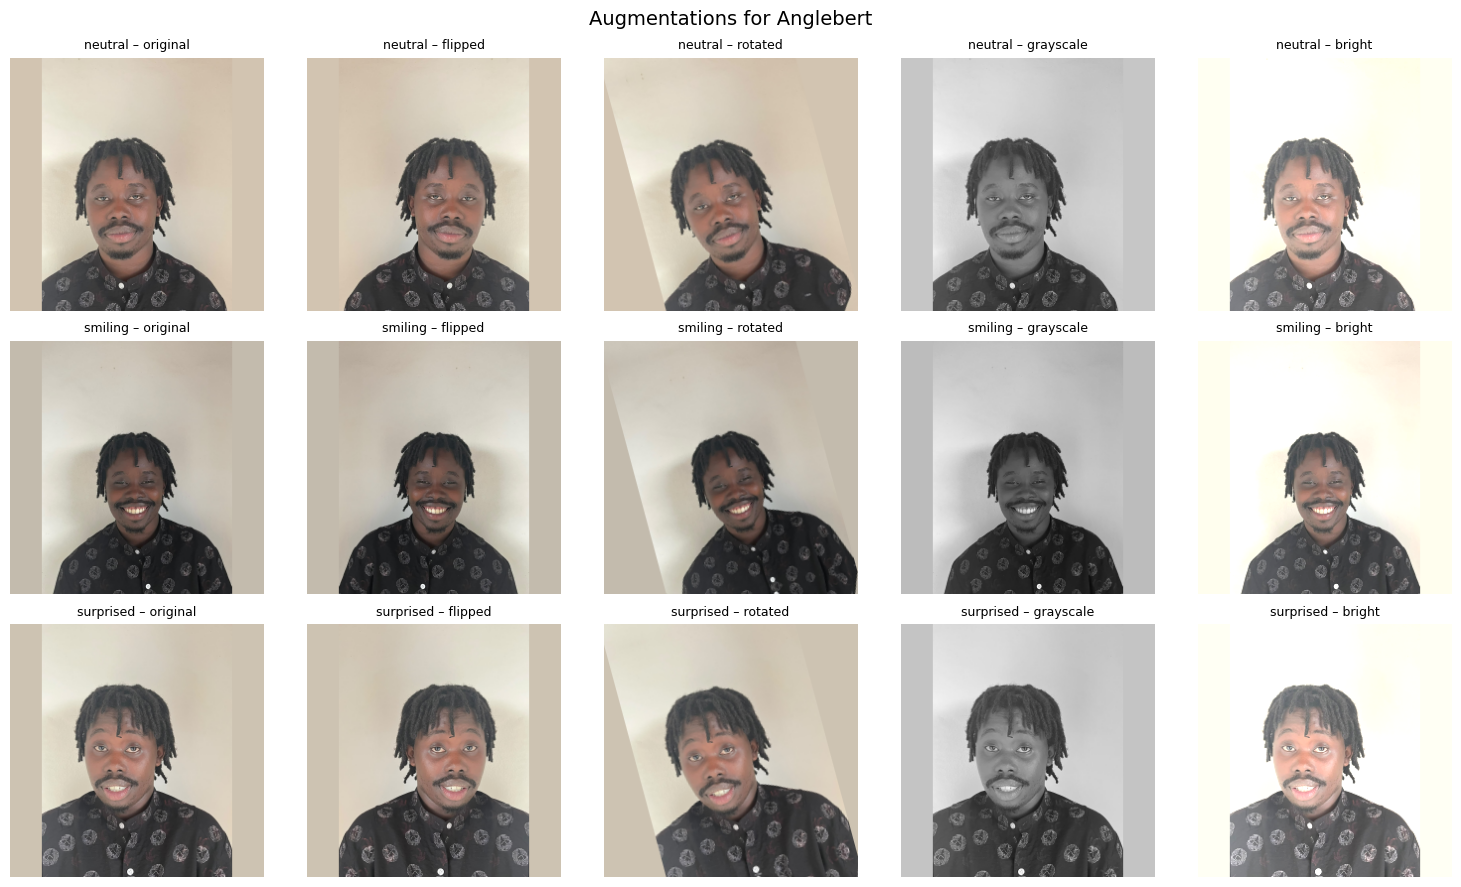

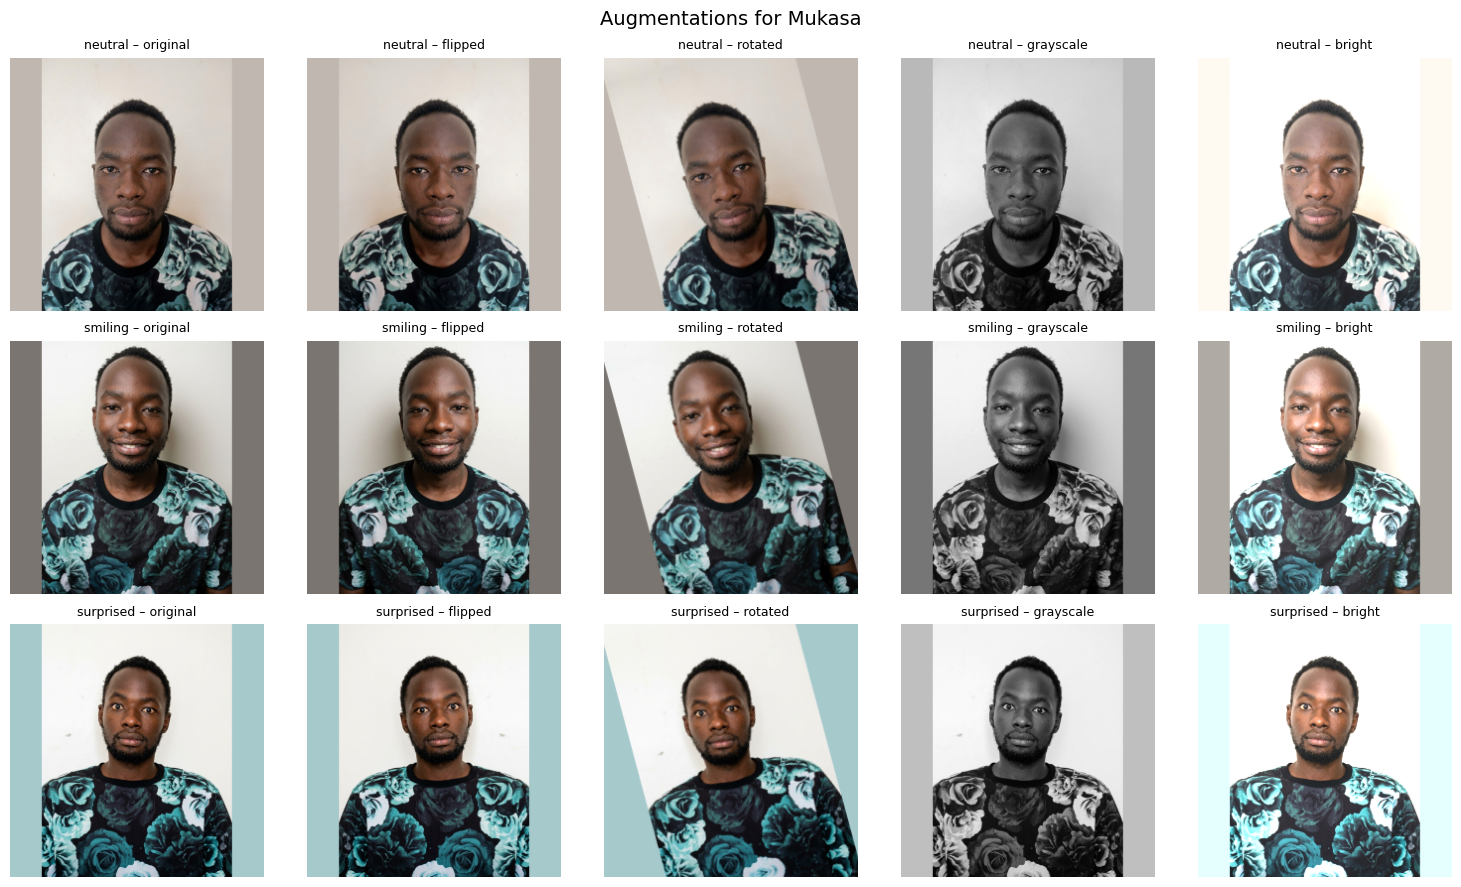

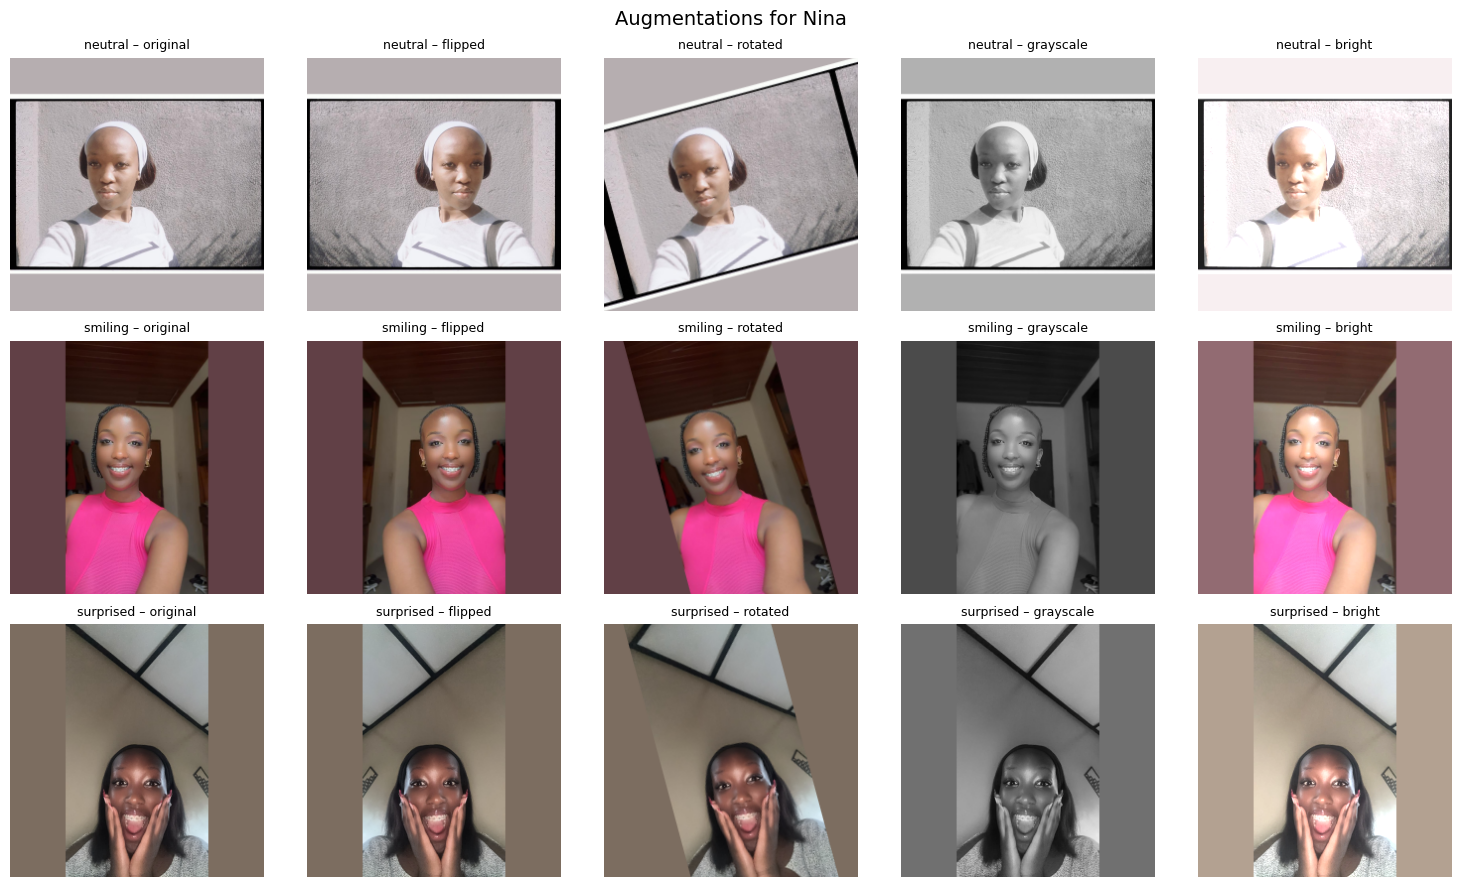

In [7]:
def display_augmentations(augmented, member):
    versions = ["original"] + list(AUGMENTATIONS.keys())
    fig, axes = plt.subplots(3, len(versions), figsize=(3 * len(versions), 9))
    for row, exp in enumerate(EXPRESSIONS):
        for col, aug_name in enumerate(versions):
            ax = axes[row][col]
            ax.imshow(augmented[member][exp][aug_name])
            ax.set_title(f"{exp} – {aug_name}", fontsize=9)
            ax.axis("off")
    plt.suptitle(f"Augmentations for {member}", fontsize=14)
    plt.tight_layout()
    plt.show()


for member in augmented:
    display_augmentations(augmented, member)

Each original was augmented 4 ways (flip, 15° rotation, grayscale, brightness/contrast) to simulate head tilt, mirrored pose, lighting changes and colour loss. This way the model learns identity rather than one exact capture. Grayscale images stay 3-channel so all images share one shape for feature extraction.

## 3. Feature extraction
**Face detection and cropping:** OpenCV Haar cascades find the largest face, which is cropped and resized to `128×128`, so the features describe the face rather than the background or clothes. Three Haar models (`alt2`, `default`, `alt`) are tried in order, and a face must fill at least 20% of the image, which rules out false hits such as a single eye. If nothing is found, `center_box` gives a fallback crop of the central 70% of the image.

In [8]:
import pandas as pd

FACE_SIZE = (128, 128)
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Several Haar models, tried in order: if one misses a face, the next gets a chance
FACE_CASCADES = [
    cv2.CascadeClassifier(cv2.data.haarcascades + name)
    for name in [
        "haarcascade_frontalface_alt2.xml",
        "haarcascade_frontalface_default.xml",
        "haarcascade_frontalface_alt.xml",
    ]
]


def detect_face(image):
    """Return the largest face box (x, y, w, h), or None if no model finds a face."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    min_side = int(image.shape[0] * 0.2)  # a face must fill at least 20% of the image (blocks tiny false hits, e.g. an eye)
    for cascade in FACE_CASCADES:
        faces = cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3,
                                         minSize=(min_side, min_side))
        if len(faces) > 0:
            return max(faces, key=lambda f: f[2] * f[3])
    return None


def center_box(image, ratio=0.7):
    """Fallback box: the central 70% of the image."""
    h, w = image.shape[:2]
    bw, bh = int(w * ratio), int(h * ratio)
    return ((w - bw) // 2, (h - bh) // 2, bw, bh)


def crop_face(image, box):
    x, y, w, h = box
    return cv2.resize(image[y:y + h, x:x + w], FACE_SIZE, interpolation=cv2.INTER_AREA)

**Feature functions:** each face gives 660 values in 4 groups:

| Group | Columns | Captures |
|---|---|---|
| Intensity stats | `mean, std, min, max` (4) | overall brightness and contrast |
| Colour histogram | `hist_{r,g,b}_0..15` (48) | skin tone and colour distribution |
| LBP histogram | `lbp_0..31` (32) | skin texture (compares each pixel with its 8 neighbours) |
| HOG | `hog_0..575` (576) | edges and shape of eyes, nose, mouth and jaw |

HOG and LBP carry most of the identity information.

In [9]:
def intensity_stats(face):
    gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
    return {
        "mean": float(gray.mean()),
        "std": float(gray.std()),
        "min": int(gray.min()),
        "max": int(gray.max()),
    }


def color_histogram(face, bins=16):
    feats = {}
    for i, ch in enumerate(["r", "g", "b"]):
        hist = cv2.calcHist([face], [i], None, [bins], [0, 256]).flatten()
        hist /= hist.sum()  # normalise so image size doesn't matter
        feats.update({f"hist_{ch}_{j}": float(v) for j, v in enumerate(hist)})
    return feats


def lbp_histogram(face, bins=32):
    """Local Binary Pattern: compares each pixel with its 8 neighbours."""
    gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY).astype(np.int16)
    center = gray[1:-1, 1:-1]
    codes = np.zeros_like(center, dtype=np.uint8)
    neighbours = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
    for bit, (dy, dx) in enumerate(neighbours):
        neighbour = gray[1 + dy:gray.shape[0] - 1 + dy, 1 + dx:gray.shape[1] - 1 + dx]
        codes |= ((neighbour >= center).astype(np.uint8) << bit)
    hist, _ = np.histogram(codes, bins=bins, range=(0, 256))
    hist = hist / hist.sum()
    return {f"lbp_{i}": float(v) for i, v in enumerate(hist)}


hog = cv2.HOGDescriptor(
    _winSize=(64, 64), _blockSize=(16, 16), _blockStride=(16, 16),
    _cellSize=(8, 8), _nbins=9,
)


def hog_features(face):
    gray = cv2.cvtColor(cv2.resize(face, (64, 64)), cv2.COLOR_RGB2GRAY)
    vec = hog.compute(gray).flatten()
    return {f"hog_{i}": float(v) for i, v in enumerate(vec)}


def extract_features(face):
    feats = {}
    feats.update(intensity_stats(face))
    feats.update(color_histogram(face))
    feats.update(lbp_histogram(face))
    feats.update(hog_features(face))
    return feats

**Run on every image and save the CSV:** detects the face on the original first. If an augmented version fails detection, it reuses the original's box (mirrored for flipped images, otherwise the face would be cropped on the wrong side). Each image becomes one row: `member_id`, `expression`, `augmentation`, `face_detected`, then the 660 features.

In [10]:
rows, crops = [], {}

for member, exps in augmented.items():
    for exp, versions in exps.items():
        # Detect on the original first; augmented versions fall back to this box
        orig_box = detect_face(versions["original"])
        orig_detected = orig_box is not None
        if orig_box is None:
            orig_box = center_box(versions["original"])

        for aug_name, img in versions.items():
            box = detect_face(img)
            detected = box is not None
            if box is None:
                x, y, w, h = orig_box
                # A flipped image needs the box mirrored horizontally
                box = (img.shape[1] - x - w, y, w, h) if aug_name == "flipped" else orig_box

            face = crop_face(img, box)
            crops[(member, exp, aug_name)] = face

            row = {
                "member_id": member,
                "expression": exp,
                "augmentation": aug_name,
                "face_detected": detected,
            }
            row.update(extract_features(face))
            rows.append(row)

features_df = pd.DataFrame(rows)
csv_path = os.path.join(OUTPUT_DIR, "image_features.csv")
features_df.to_csv(csv_path, index=False)

print(f"Saved {csv_path}: {features_df.shape[0]} rows × {features_df.shape[1]} columns")
print(f"Faces detected directly: {features_df['face_detected'].sum()}/{len(features_df)}")

Saved output/image_features.csv: 45 rows × 664 columns
Faces detected directly: 42/45


**Check the output:**
1. Cropped-face preview: confirms the crops contain faces.
2. CSV quality: null count, and a check that every member has all 5 versions × 3 expressions.
3. Boxplot: whether mean intensity alone differs between members.

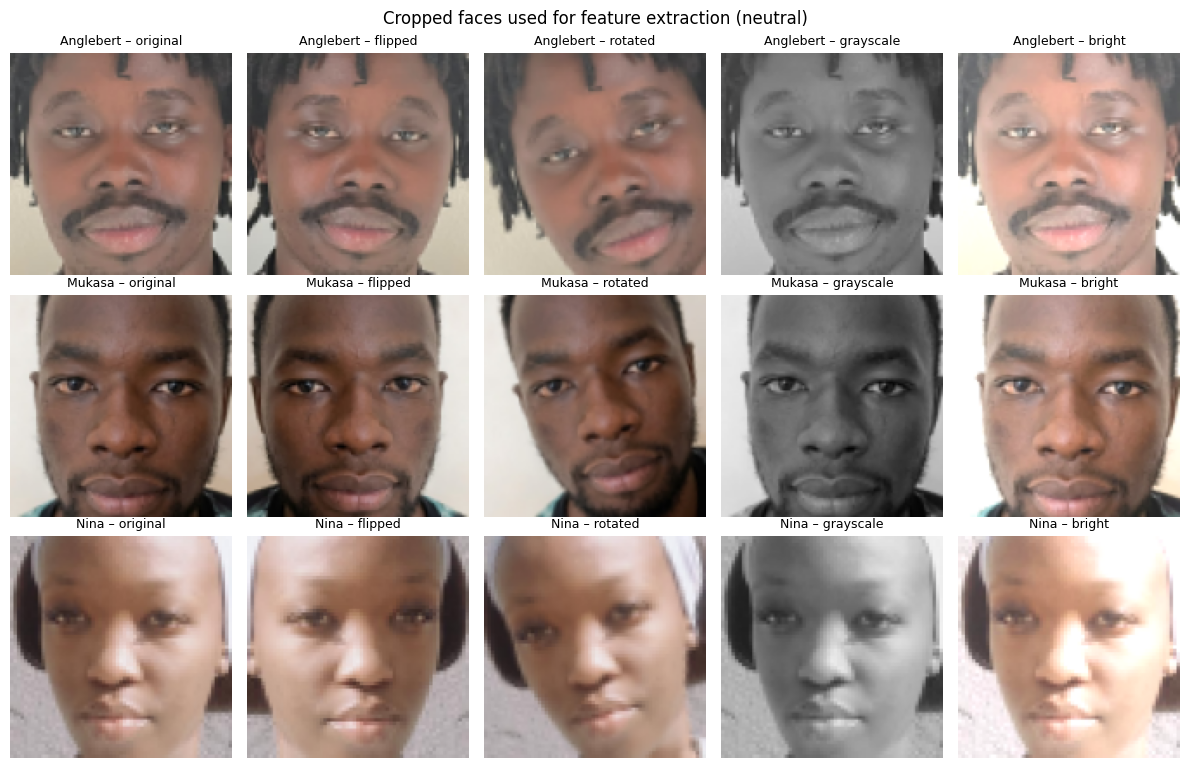

Nulls: 0
augmentation  bright  flipped  grayscale  original  rotated
member_id                                                  
Anglebert          3        3          3         3        3
Mukasa             3        3          3         3        3
Nina               3        3          3         3        3


,member_id,expression,augmentation,mean,std,min,max
0,Anglebert,neutral,original,121.270874,32.748921,23,214
1,Anglebert,neutral,flipped,119.342163,35.234099,24,215
2,Anglebert,neutral,rotated,121.888916,34.074111,50,215
3,Anglebert,neutral,grayscale,121.280273,32.745945,23,215
4,Anglebert,neutral,bright,173.313110,38.023701,59,255
5,Anglebert,smiling,original,87.325012,43.480724,13,235
6,Anglebert,smiling,flipped,85.290894,35.875039,13,235
7,Anglebert,smiling,rotated,90.196228,44.584499,15,232
8,Anglebert,smiling,grayscale,87.325378,43.480802,13,235
9,Anglebert,smiling,bright,134.154907,49.308163,49,255


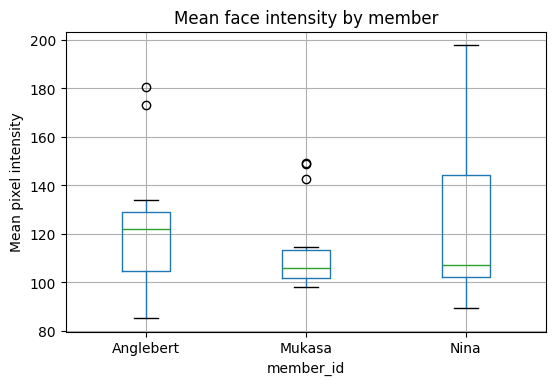

In [11]:
# 1. Faces were cropped correctly
fig, axes = plt.subplots(len(augmented), 5, figsize=(12, 2.6 * len(augmented)), squeeze=False)
for r, member in enumerate(augmented):
    for c, aug in enumerate(["original", "flipped", "rotated", "grayscale", "bright"]):
        axes[r][c].imshow(crops[(member, "neutral", aug)])
        axes[r][c].set_title(f"{member} – {aug}", fontsize=9)
        axes[r][c].axis("off")
plt.suptitle("Cropped faces used for feature extraction (neutral)")
plt.tight_layout()
plt.show()

# 2. CSV quality
print("Nulls:", features_df.isnull().sum().sum())
print(features_df.groupby(["member_id", "augmentation"]).size().unstack())
display(features_df[["member_id", "expression", "augmentation", "mean", "std", "min", "max"]].head(10))

# 3. Do the features separate members?
features_df.boxplot(column="mean", by="member_id", figsize=(6, 4))
plt.title("Mean face intensity by member")
plt.suptitle("")
plt.ylabel("Mean pixel intensity")
plt.show()

## Summary
- **Members processed:** 3 (Anglebert, Mukasa, Nina), each with neutral, smiling and surprised images
- **Images:** 9 originals → 45 after 4 augmentations (flip, rotation, grayscale, brightness)
- **Face detection:** 42/45 detected directly, including all 9 originals. The 3 misses are rotated images (Haar models are trained on upright faces); those reused the original image's box, and the crop preview above confirms every crop is a face.
- **Features:** 660 per image (intensity stats, RGB histograms, LBP, HOG), saved to `output/image_features.csv` (45 rows × 664 columns, no nulls)
- **Observation:** mean face intensity overlaps heavily between members (Anglebert ≈ 122, Mukasa ≈ 113, Nina ≈ 125 on average, all spanning roughly 85–200). Brightness alone can't identify a person, so the model has to rely on the HOG and LBP features.
- **Limitations:** the dataset is small (15 images per member). Augmented versions of the same original should stay on the same side of the train/test split, or scores will be inflated. Deep embeddings (e.g. FaceNet) would be more robust in real-world use; handcrafted features were chosen because they are transparent and suit a small, controlled dataset.
- **Next step:** `image_features.csv` is the input to the facial recognition model, with `member_id` as the label.
